# Bullet Chart

**Family:** Magnitude &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Magnitude:* Compare sizes, relative or absolute (usually counts rather than rates).

## Design purpose

Stephen Few's compact replacement for gauges. A bar shows the actual value, a tick marks the target, and shaded bands mark qualitative ranges (poor, ok, good), all in a small strip.

## When to use

- Show KPI performance against target and qualitative thresholds in dashboards
- Fit many metrics into little space (stack them vertically)

## Avoid when

- There is no target or benchmark
- The audience is unfamiliar with it and has no legend to explain it

## Alternatives

- KPI stat tile
- Bar with reference line

## Design tips

- Bands are shades of gray; the bar is the only strong color

## Example

Five quarterly KPIs versus target, each with poor/satisfactory/good ranges.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
df = pd.DataFrame([
    ("Revenue ($M)", 270, 250, [150, 225, 300]),
    ("Profit (%)", 22.5, 26, [20, 25, 30]),
    ("Avg. order ($)", 320, 550, [350, 500, 600]),
    ("New customers", 1650, 2100, [1400, 2000, 2500]),
    ("Satisfaction (1–5)", 4.5, 4.2, [3.5, 4.25, 5]),
], columns=["kpi", "actual", "target", "ranges"])
df

,kpi,actual,target,ranges
0,Revenue ($M),270.0,250.0,"[150, 225, 300]"
1,Profit (%),22.5,26.0,"[20, 25, 30]"
2,Avg. order ($),320.0,550.0,"[350, 500, 600]"
3,New customers,1650.0,2100.0,"[1400, 2000, 2500]"
4,Satisfaction (1–5),4.5,4.2,"[3.5, 4.25, 5]"


### Plot

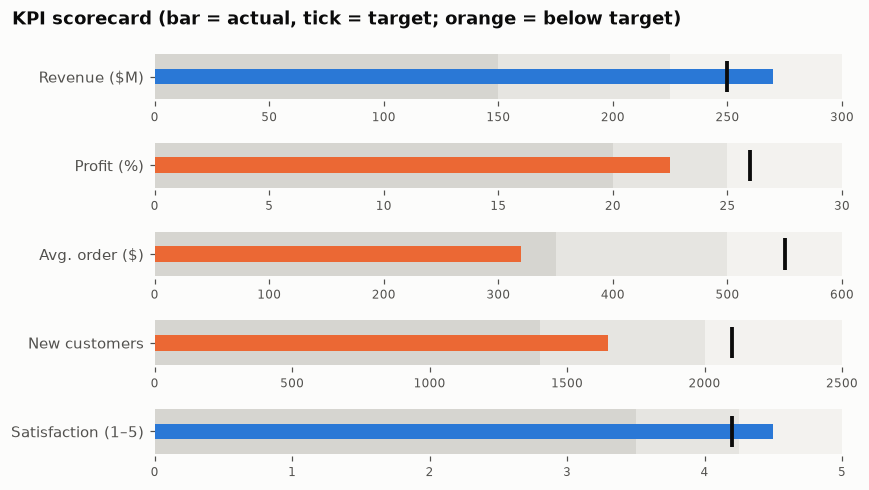

In [3]:
fig, axes = plt.subplots(len(df), 1, figsize=(8, 4.5))
band_colors = ["#d6d5d0", "#e6e5e1", "#f3f2ef"]
for ax, (_, r) in zip(axes, df.iterrows()):
    prev = 0
    for upper, c in zip(r["ranges"], band_colors):
        ax.barh(0, upper - prev, left=prev, color=c, height=1)
        prev = upper
    ax.barh(0, r["actual"], color=PALETTE[0] if r["actual"] >= r["target"] else PALETTE[1],
            height=0.35)
    ax.vlines(r["target"], -0.35, 0.35, color="#0b0b0b", linewidth=2.5)
    ax.set_xlim(0, r["ranges"][-1])
    ax.set_yticks([0], [r["kpi"]])
    ax.grid(False)
    ax.tick_params(axis="x", labelsize=8)
    for s in ["left", "bottom"]:
        ax.spines[s].set_visible(False)
fig.suptitle("KPI scorecard (bar = actual, tick = target; orange = below target)",
             x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

Each row is one KPI. The inner bar is the actual value and the black tick is the target. The gray bands mark poor, satisfactory and good. Orange bars missed the target.

---
Standalone script: [`bullet_chart.py`](bullet_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)